In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv(r"OnlineRetail.csv", encoding='unicode_escape')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
print("Dataset shape:", df.shape)

# Check missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
print(missing_summary)

Dataset shape: (541909, 8)
             Missing Values  Missing Percentage
InvoiceNo                 0                0.00
StockCode                 0                0.00
Description            1454                0.27
Quantity                  0                0.00
InvoiceDate               0                0.00
UnitPrice                 0                0.00
CustomerID           135080               24.93
Country                   0                0.00


In [8]:
df_clean = df.copy()

df_clean = df_clean.dropna(subset=["CustomerID"])

df_clean = df_clean.dropna(subset=["Description"])

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Original shape: (541909, 8)
Cleaned shape: (406829, 8)

Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [9]:
df_clean[df_clean.duplicated(keep=False)].sort_values(
    by=["InvoiceNo", "StockCode"]
).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,12/1/2010 11:49,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/2010 11:49,1.65,17920.0,United Kingdom


In [10]:
duplicate_count = df_clean.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining exact duplicates:", df_clean.duplicated().sum())


Exact duplicate rows: 5225
Shape after removing duplicates: (401604, 8)
Remaining exact duplicates: 0


In [11]:
print("Negative quantities:",
      (df_clean["Quantity"] < 0).sum())

print("Zero quantities:",
      (df_clean["Quantity"] == 0).sum())

print("Negative prices:",
      (df_clean["UnitPrice"] < 0).sum())

print("Zero prices:",
      (df_clean["UnitPrice"] == 0).sum())

print("Cancelled invoice rows:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())


Negative quantities: 8872
Zero quantities: 0
Negative prices: 0
Zero prices: 40


Cancelled invoice rows: 8872


In [12]:

# Inspect cancellation-related transactions
cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print(cancelled[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]
].head(10))

# Check whether all cancelled invoice rows have negative quantities
print(
    "Cancelled rows with non-negative quantity:",
    (cancelled["Quantity"] >= 0).sum()
)

# Inspect zero-price transactions
print(
    df_clean.loc[
        df_clean["UnitPrice"] == 0,
        ["InvoiceNo", "Description", "Quantity", "CustomerID"]
    ].head(10)
)


    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

     UnitPrice  CustomerID  
141      27.50     14527.0  
154       4.65     15311.0  
235       1.65     17548.0  
236       0.29     17548.0  
237       0.29     17548.0  
238       0.29     17548.0  
239 

In [13]:

sales_df = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print(sales_df.shape)


(392732, 8)


In [14]:
sales_df["TotalAmount"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

sales_df[[
    "CustomerID",
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "TotalAmount"
]].head()

,CustomerID,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,17850.0,536365,6,2.55,15.30
1,17850.0,536365,6,3.39,20.34
2,17850.0,536365,8,2.75,22.00
3,17850.0,536365,6,3.39,20.34
4,17850.0,536365,6,3.39,20.34


In [15]:
customer_data = sales_df.groupby("CustomerID").agg(
    Monetary=("TotalAmount", "sum"),
    Frequency=("InvoiceNo", "nunique"),
    Quantity=("Quantity", "sum")
).reset_index()

customer_data.head()


,CustomerID,Monetary,Frequency,Quantity
0,12346.0,77183.60,1,74215
1,12347.0,4310.00,7,2458
2,12348.0,1797.24,4,2341
3,12349.0,1757.55,1,631
4,12350.0,334.40,1,197


In [16]:
# Convert InvoiceDate to datetime
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"],
    format="%m/%d/%Y %H:%M"
)

# Set reference date to the day after the latest transaction
reference_date = sales_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

# Calculate recency for each customer
recency_data = sales_df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max")
).reset_index()

recency_data["Recency"] = (
    reference_date - recency_data["LastPurchase"].dt.normalize()
).dt.days

recency_data.head()


,CustomerID,LastPurchase,Recency
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,3
2,12348.0,2011-09-25 13:13:00,76
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,311


In [17]:
# Combine customer features with Recency
customer_data = customer_data.merge(
    recency_data[["CustomerID", "Recency"]],
    on="CustomerID",
    how="left"
)

# View the combined table
print(customer_data.shape)
customer_data.head()


(4339, 5)


,CustomerID,Monetary,Frequency,Quantity,Recency
0,12346.0,77183.60,1,74215,326
1,12347.0,4310.00,7,2458,3
2,12348.0,1797.24,4,2341,76
3,12349.0,1757.55,1,631,19
4,12350.0,334.40,1,197,311


In [18]:
print("Dataset shape:", customer_data.shape)

print("\nMissing values:")
print(customer_data.isnull().sum())

print("\nDuplicate rows:", customer_data.duplicated().sum())

Dataset shape: (4339, 5)

Missing values:
CustomerID    0
Monetary      0
Frequency     0
Quantity      0
Recency       0
dtype: int64

Duplicate rows: 0


In [19]:
from sklearn.preprocessing import StandardScaler

features = customer_data[["Recency", "Frequency", "Monetary"]]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_features_df = pd.DataFrame(scaled_features, columns=features.columns,index =features.index)


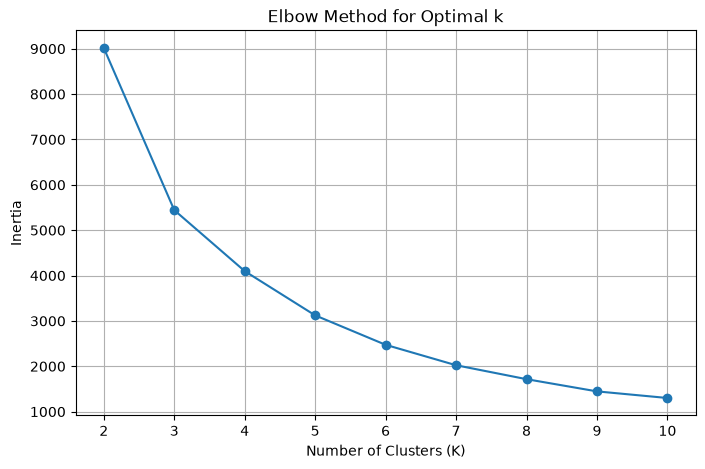

In [20]:
from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2,11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42,n_init=10)
    kmeans.fit(scaled_features_df)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.xticks(k_values)
plt.grid(True)
plt.show()


In [21]:
for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}, Inertia = {inertia:.2f}")

K = 2, Inertia = 9016.11
K = 3, Inertia = 5442.73
K = 4, Inertia = 4097.89
K = 5, Inertia = 3122.61
K = 6, Inertia = 2473.77
K = 7, Inertia = 2023.34
K = 8, Inertia = 1716.10
K = 9, Inertia = 1446.91
K = 10, Inertia = 1301.13


In [22]:
kmeans = KMeans(n_clusters=4, random_state=42,n_init=10)
customer_data["Cluster"] = kmeans.fit_predict(scaled_features)
customer_data.head()

,CustomerID,Monetary,Frequency,Quantity,Recency,Cluster
0,12346.0,77183.60,1,74215,326,0
1,12347.0,4310.00,7,2458,3,3
2,12348.0,1797.24,4,2341,76,3
3,12349.0,1757.55,1,631,19,3
4,12350.0,334.40,1,197,311,1


In [23]:
cluster_summary = customer_data.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)
print(cluster_summary)    

         CustomerCount  AvgRecency  AvgFrequency  AvgMonetary
Cluster                                                      
0                  211       16.12         22.05     12435.09
1                 1061      249.17          1.55       476.42
2                   13        7.62         82.69    127187.96
3                 3054       44.48          3.66      1343.97


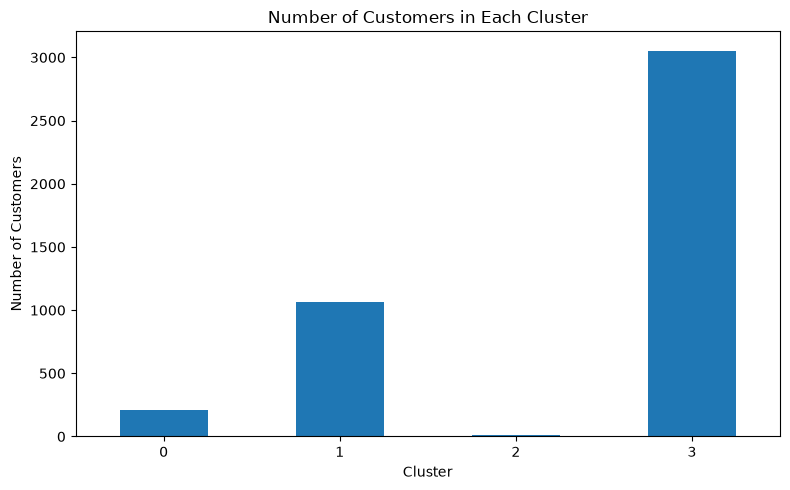

In [24]:
cluster_summary["CustomerCount"].plot(kind='bar', figsize=(8, 5), title = "Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
customer_data.nlargest(10, "Monetary")[
    ["CustomerID", "Monetary", "Frequency", "Recency", "Cluster"]
]

,CustomerID,Monetary,Frequency,Recency,Cluster
1690,14646.0,280206.02,74,2,2
4202,18102.0,259657.30,60,1,2
3729,17450.0,194390.79,46,9,2
3009,16446.0,168472.50,2,1,2
1880,14911.0,143711.17,201,2,2
55,12415.0,124914.53,21,25,2
1334,14156.0,117210.08,55,10,2
3772,17511.0,91062.38,31,3,2
2703,16029.0,80850.84,63,39,2
0,12346.0,77183.60,1,326,0


In [26]:
print(customer_data["Monetary"].describe())

print(
    "\nMonetary skewness:",
    round(customer_data["Monetary"].skew(), 2)
)

count      4339.000000
mean       2048.215924
std        8984.248352
min           0.000000
25%         306.455000
50%         668.560000
75%        1660.315000
max      280206.020000
Name: Monetary, dtype: float64

Monetary skewness: 19.34


In [27]:
features_log = features.copy()
features_log["Monetary"] = np.log1p(features_log["Monetary"])
print(
    "\nMonetary skewness after log transformation:",
    round(features_log["Monetary"].skew(), 2)
)


Monetary skewness after log transformation: 0.36


In [29]:
from sklearn.preprocessing import StandardScaler

scaler_log = StandardScaler()

scaled_features_log = scaler_log.fit_transform(
    features_log
)

In [30]:
kmeans_log = KMeans(n_clusters=4, random_state=42,n_init=10)
customer_data["Cluster_Log"] = kmeans_log.fit_predict(scaled_features_log)
customer_data.head()

,CustomerID,Monetary,Frequency,Quantity,Recency,Cluster,Cluster_Log
0,12346.0,77183.60,1,74215,326,0,2
1,12347.0,4310.00,7,2458,3,3,2
2,12348.0,1797.24,4,2341,76,3,2
3,12349.0,1757.55,1,631,19,3,0
4,12350.0,334.40,1,197,311,1,1


In [31]:
cluster_log_summary = customer_data.groupby("Cluster_Log").agg(
    CustomerCount=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)
print(cluster_log_summary)

             CustomerCount  AvgRecency  AvgFrequency  AvgMonetary
Cluster_Log                                                      
0                     2087       52.79          2.23       597.16
1                     1012      252.99          1.46       405.96
2                     1218       30.68          8.79      4550.79
3                       22        6.09         77.55     76692.33


In [32]:
from sklearn.metrics import silhouette_score
score_original = silhouette_score(scaled_features, customer_data["Cluster"])
score_log = silhouette_score(scaled_features_log, customer_data["Cluster_Log"])
print(f"Silhouette Score (Original): {round(score_original, 2)}")
print(f"Silhouette Score (Log Transformed): {round(score_log, 2)}")

Silhouette Score (Original): 0.62
Silhouette Score (Log Transformed): 0.42


In [34]:
cluster_check = customer_data.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),  
    MedianSpend=("Monetary", "median"),
    MedianRecency=("Recency", "median"),
    MedianFrequency=("Frequency", "median"),
    MaxSpend=("Monetary", "max"),
    MinSpend=("Monetary", "min")
).round(2)
print(cluster_check)    

         CustomerCount  MedianSpend  MedianRecency  MedianFrequency  \
Cluster                                                               
0                  211      7834.65            6.0             19.0   
1                 1061       309.80          244.0              1.0   
2                   13    117210.08            2.0             63.0   
3                 3054       819.62           33.0              3.0   

          MaxSpend  MinSpend  
Cluster                       
0         77183.60   1296.44  
1          9864.26      3.75  
2        280206.02  33053.19  
3         21429.39      0.00  


In [35]:
dashboard_data = customer_data[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster"
    ]
].copy()

dashboard_data.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,0
1,12347.0,3,7,4310.00,3
2,12348.0,76,4,1797.24,3
3,12349.0,19,1,1757.55,3
4,12350.0,311,1,334.40,1


In [38]:
segment_names = {
    0: "High Value",
    1: "At-Risk Customers",
    2: "Exceptional High Spenders",
    3: "Regular Customers"
}
dashboard_data["Segment"] = dashboard_data["Cluster"].map(segment_names)
dashboard_data[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head()


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,0,High Value
1,12347.0,3,7,4310.00,3,Regular Customers
2,12348.0,76,4,1797.24,3,Regular Customers
3,12349.0,19,1,1757.55,3,Regular Customers
4,12350.0,311,1,334.40,1,At-Risk Customers


In [39]:
dashboard_data["Segment"].value_counts()

Segment
Regular Customers            3054
At-Risk Customers            1061
High Value                    211
Exceptional High Spenders      13
Name: count, dtype: int64

In [42]:
total_customers = dashboard_data["CustomerID"].nunique()
total_revenue = dashboard_data["Monetary"].sum()
avg_customer_spend = dashboard_data["Monetary"].mean()
total_segments = dashboard_data["Segment"].nunique()

print(f"Total Customers: {total_customers:,}")
print(f"Total Revenue:",f"£{total_revenue:,.2f}")
print(f"Average Customer Spend: £{avg_customer_spend:,.2f}")
print(f"Total Segments: {total_segments}")

Total Customers: 4,339
Total Revenue: £8,887,208.89
Average Customer Spend: £2,048.22
Total Segments: 4


In [44]:
dashboard_data.to_csv("customer_segments.csv", index=False)